## Импорт библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Lasso, ElasticNetCV
from sklearn.metrics import r2_score

sns.set_theme(style="whitegrid")

Подключение библиотек

## Подготовка данных и матрица корреляций

In [3]:
df = pd.read_csv("AmesHousing.csv")
features = [
    "Gr Liv Area", "Overall Qual", "Year Built", "TotRms AbvGrd",
    "Garage Cars", "Garage Area", "Total Bsmt SF",
    "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF",
]
data = df.dropna(subset=features + ["SalePrice"])
X = data[features]
y = data["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
corr_matrix = X_train.corr()
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(corr_matrix.round(2).to_string())

               Gr Liv Area  Overall Qual  Year Built  TotRms AbvGrd  Garage Cars  Garage Area  Total Bsmt SF  BsmtFin SF 1  BsmtFin SF 2  Bsmt Unf SF
Gr Liv Area           1.00          0.56        0.23           0.80         0.48         0.47           0.42          0.20         -0.01         0.21
Overall Qual          0.56          1.00        0.59           0.36         0.60         0.55           0.54          0.28         -0.03         0.25
Year Built            0.23          0.59        1.00           0.09         0.53         0.47           0.40          0.28         -0.03         0.11
TotRms AbvGrd         0.80          0.36        0.09           1.00         0.33         0.30           0.25          0.03         -0.05         0.24
Garage Cars           0.48          0.60        0.53           0.33         1.00         0.89           0.43          0.25         -0.00         0.17
Garage Area           0.47          0.55        0.47           0.30         0.89         1.00       

В матрице видна сильная связь между площадью гаража (Garage Area) и числом мест для машин (Garage Cars)

## Обучение моделей и сравнение коэффициентов

In [9]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]

ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)

lasso_cv = LassoCV(alphas=alphas_to_test, random_state=42, max_iter=50000)
lasso_cv.fit(X_train, y_train)

lasso = Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)

l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(
    l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5,
    random_state=42, max_iter=50000
)
elastic_cv.fit(X_train, y_train)

print(f"Alpha для Ridge: {ridge_cv.alpha_}")
print(f"Alpha для Lasso: {lasso_cv.alpha_}")
print(f"Alpha для ElasticNet: {elastic_cv.alpha_}")
print(f"Доля L1 для ElasticNet: {elastic_cv.l1_ratio_}")

print("Признаки:", X.columns.to_list())
print("Веса OLS:", np.round(lr.coef_, 0))
print("Веса Ridge:", np.round(ridge_cv.coef_, 0))
print("Веса Lasso CV:", np.round(lasso_cv.coef_, 0))
print("Веса Lasso:", np.round(lasso.coef_, 0))
print("Веса ElasticNet:", np.round(elastic_cv.coef_, 0))

Alpha для Ridge: 100.0
Alpha для Lasso: 1000.0
Alpha для ElasticNet: 0.1
Доля L1 для ElasticNet: 0.7
Признаки: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'TotRms AbvGrd', 'Garage Cars', 'Garage Area', 'Total Bsmt SF', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF']
Веса OLS: [25513. 29452.  8975.  -485.  4199.  5984.  8763.  9311.  1931. -1744.]
Веса Ridge: [23145. 28032.  9181.  1433.  4923.  6100.  9071.  9395.  1919. -1521.]
Веса Lasso CV: [24447. 29439.  8427.     0.  4005.  5940.  7166. 10407.  1560.    -0.]
Веса Lasso: [21968. 29465.  6235.     0.  3464.  5439.  7104.  7732.     0.    -0.]
Веса ElasticNet: [23750. 28441.  9125.   951.  4734.  6059.  8992.  9380.  1926. -1585.]


При сильном штрафе (5000) у Lasso обнулены веса числа комнат и части признаков подвала

## График весов признаков

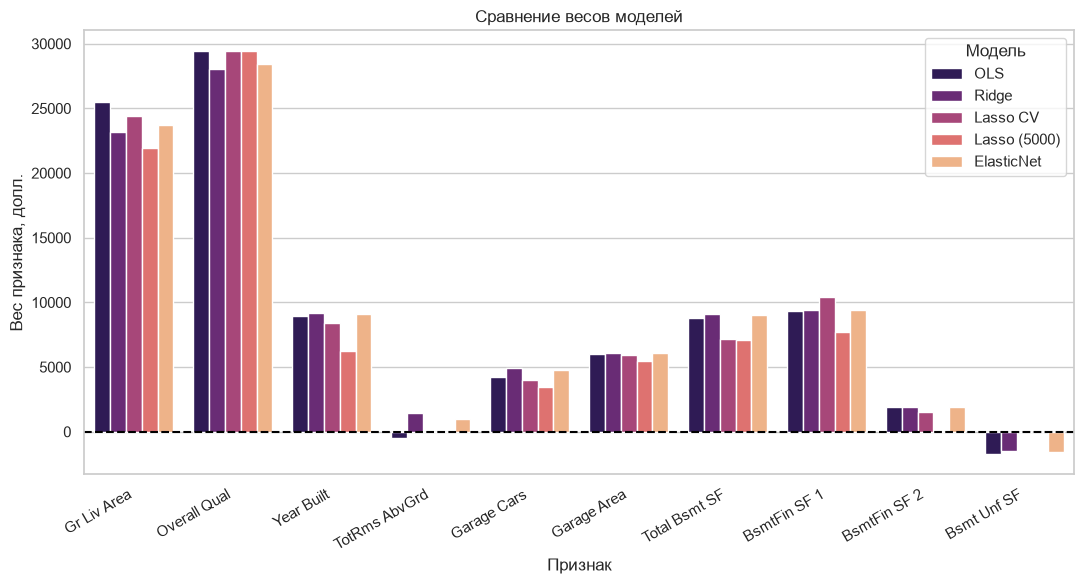

In [6]:
weights_df = pd.DataFrame({
    "Признак": X.columns,
    "OLS": lr.coef_,
    "Ridge": ridge_cv.coef_,
    "Lasso CV": lasso_cv.coef_,
    "Lasso (5000)": lasso.coef_,
    "ElasticNet": elastic_cv.coef_
})

weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Вес"
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=weights_melted, x="Признак", y="Вес",
    hue="Модель", palette="magma"
)
plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Сравнение весов моделей")
plt.ylabel("Вес признака, долл.")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Модель")
plt.tight_layout()
plt.show()

На графике выделяются общая оценка качества дома(Overall Qual) и жилая площадь (Gr Liv Area)

## Сравнение моделей по R²

In [8]:
print(f"R² для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R² для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R² для Lasso CV: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R² для Lasso: {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R² для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R² для OLS: 0.7923
R² для Ridge: 0.7898
R² для Lasso CV: 0.7901
R² для Lasso: 0.7749
R² для ElasticNet: 0.7906


На тестовой выборке получены близкие значения R². Самое высокое значение получено у обычной линейной регрессии, самое низкое у Lasso и качество прогноза немного снизилось